In [1]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
Device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {Device} device")

Using cpu device


In [3]:
training_data = datasets.FashionMNIST(root="data",train=True,download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),)
test_data = datasets.FashionMNIST(root="data",train=False,download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),)

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 343kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.22MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.9MB/s]


In [4]:
batch_s = 64
train_dataloader = DataLoader(training_data, batch_size= batch_s,shuffle=True)
test_dataloader = DataLoader(test_data, batch_size = batch_s)


In [5]:
class CNN(nn.Module):

  def __init__(self):
    super().__init__()
    self.cnn_relu = nn.Sequential(nn.Conv2d(1,32,kernel_size = 3, stride = 1, padding = 0),
                                  nn.ReLU(), nn.MaxPool2d(2),
                                  nn.Conv2d(32,64,kernel_size = 3,stride = 1, padding = 0),
                                  nn.ReLU(), nn.MaxPool2d(2))
    self.flatten = nn.Flatten()
    self.classifier = nn.Sequential(nn.Linear(64*5*5,128),nn.ReLU(),nn.Linear(128,10))
  def forward(self, x):
    x = self.cnn_relu(x)
    x = self.flatten(x)
    logits = self.classifier(x)
    return logits

model = CNN().to(Device)
print(model)

CNN(
  (cnn_relu): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=1600, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [6]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = 0.001)

In [7]:
def train(train_data, model, loss_fn, optimizer):
  size = len(train_data.dataset)
  model.train()
  for batch, (X, y) in enumerate(train_data):
    X = X.to(Device)
    y = y.to(Device)
    pred = model(X)
    loss = loss_fn(pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if batch % 100 == 0:
       loss, current = loss.item(), (batch + 1) * len(X)
       print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


In [8]:
def test(test_data, model, loss_fn):
    size = len(test_data.dataset)
    num_batches = len(test_data)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in test_data:
            X, y = X.to(Device), y.to(Device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [9]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.314569  [   64/60000]
loss: 2.294859  [ 6464/60000]
loss: 2.298965  [12864/60000]
loss: 2.284384  [19264/60000]
loss: 2.314408  [25664/60000]
loss: 2.285508  [32064/60000]
loss: 2.288217  [38464/60000]
loss: 2.276461  [44864/60000]
loss: 2.260845  [51264/60000]
loss: 2.268923  [57664/60000]
Test Error: 
 Accuracy: 33.9%, Avg loss: 2.263816 

Epoch 2
-------------------------------
loss: 2.275751  [   64/60000]
loss: 2.236579  [ 6464/60000]
loss: 2.243666  [12864/60000]
loss: 2.242503  [19264/60000]
loss: 2.242997  [25664/60000]
loss: 2.225805  [32064/60000]
loss: 2.213946  [38464/60000]
loss: 2.189430  [44864/60000]
loss: 2.165201  [51264/60000]
loss: 2.150006  [57664/60000]
Test Error: 
 Accuracy: 46.8%, Avg loss: 2.141325 

Epoch 3
-------------------------------
loss: 2.133479  [   64/60000]
loss: 2.110782  [ 6464/60000]
loss: 2.090894  [12864/60000]
loss: 2.023963  [19264/60000]
loss: 1.979799  [25664/60000]
loss: 1.945768  [32064/600

In [10]:
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for X, y in test_dataloader:
        X = X.to(Device)
        pred = model(X)
        predicted = pred.argmax(1)
        y_true.extend(y.numpy())
        y_pred.extend(predicted.cpu().numpy())

In [11]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


In [12]:
model = CNN().to(Device)
model.load_state_dict(torch.load("model.pth", weights_only=True))

<All keys matched successfully>

In [13]:
classes = ["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot",]
model.eval()
x, y = test_data[0][0], test_data[0][1]
with torch.no_grad():
    x = x.unsqueeze(0).to(Device)
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "Sandal", Actual: "Ankle boot"


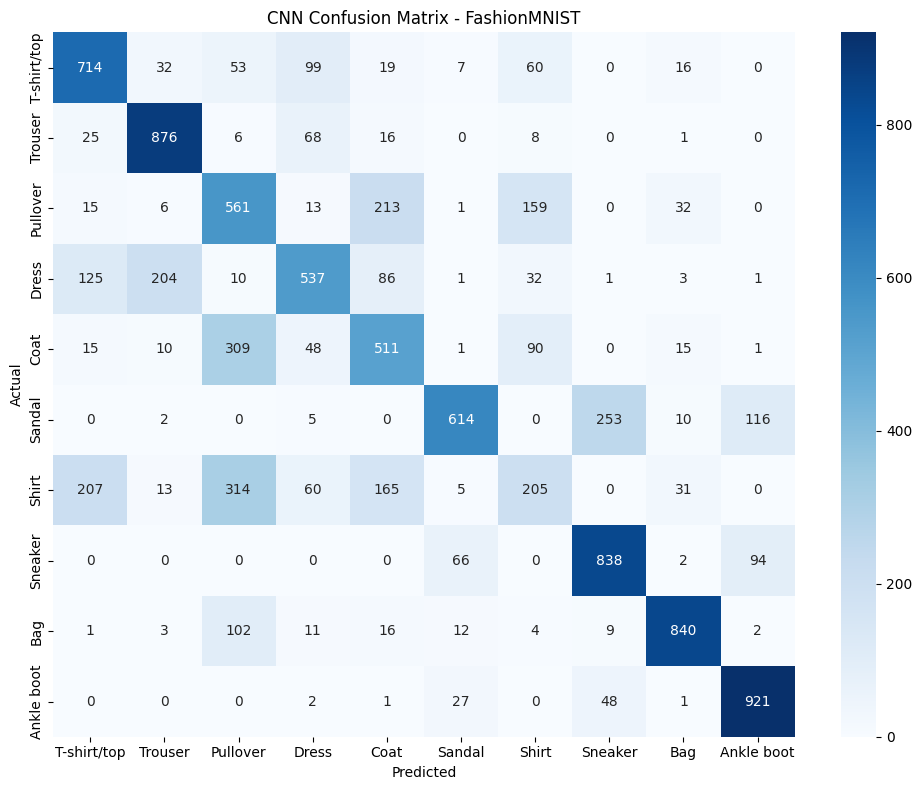

In [14]:
classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix - FashionMNIST")
plt.tight_layout()
plt.show()

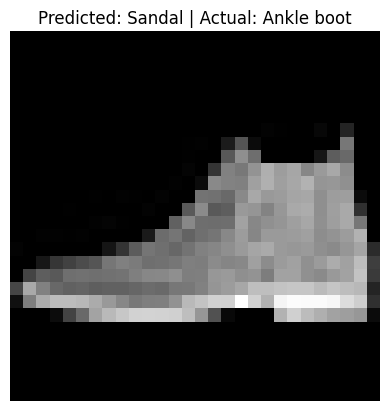

In [15]:
plt.imshow(x.cpu().squeeze(), cmap="gray")
plt.title(f"Predicted: {predicted} | Actual: {actual}")
plt.axis("off")
plt.show()

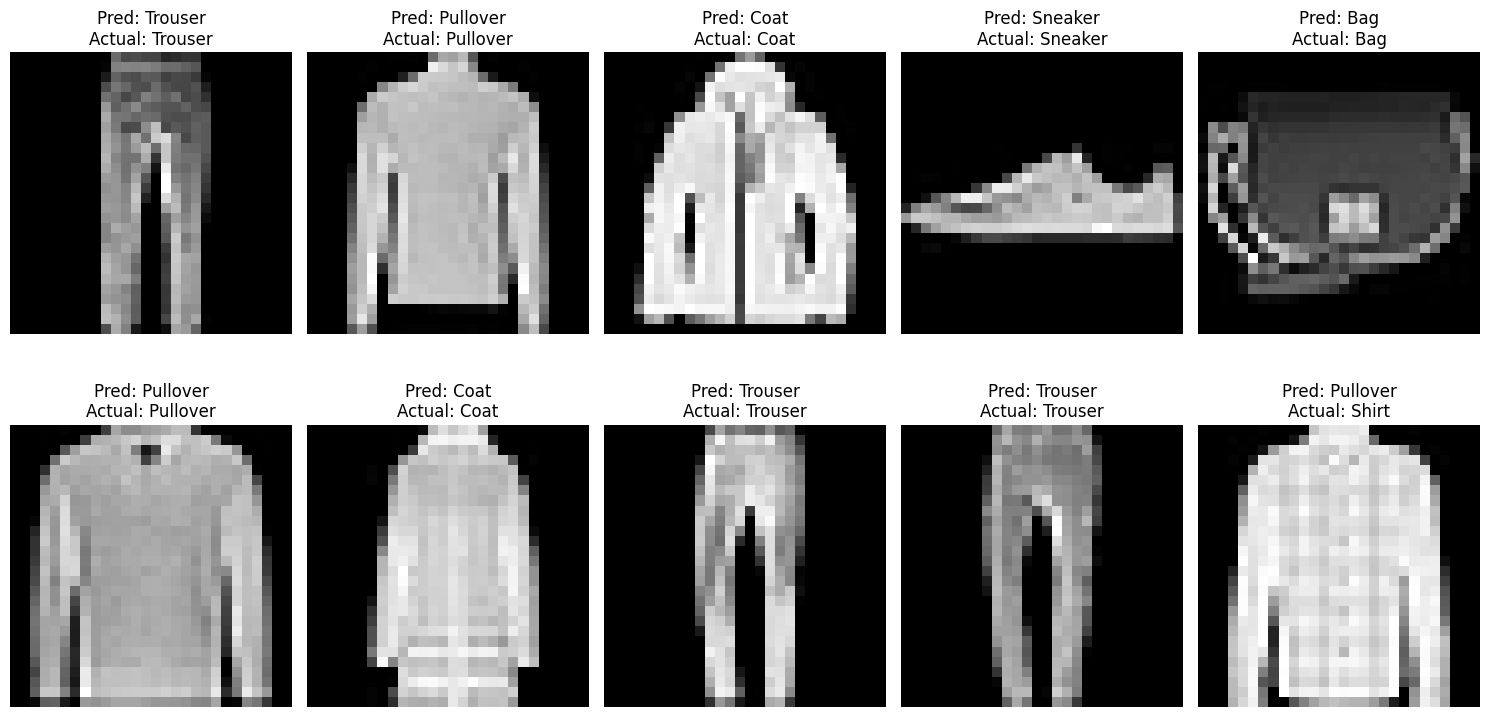

In [16]:
import random
model.eval()
plt.figure(figsize=(15, 8))
for i in range(10):
    index = random.randint(0, len(test_data)-1)
    x, y = test_data[index]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(Device))
        predicted = classes[pred.argmax(1).item()]
    plt.subplot(2, 5, i+1)
    plt.imshow(x.squeeze(), cmap="gray")
    plt.title(f"Pred: {predicted}\nActual: {classes[y]}")
    plt.axis("off")
plt.tight_layout()
plt.show()